# 📊 광고 A/B 테스트 데이터셋 분석

## 📘 SmartAd BIO A/B 테스트 데이터 설명

### 📝 개요
-  **BIO 질문**: 광고(exposed는 인터랙티브 광고, control은 더미 광고)를 본 뒤 "이 브랜드를 알고 있나요?"에 Yes / No로 답한다. (yes = 안다, no = 모른다)
- **auction_id**는 노출(impression) 단위의 고유 ID이며, 사용자가 설문을 보고도 응답하지 않을 수 있음 (이 경우 `yes`, `no` 모두 0)

### 🧪 실험 그룹
| 그룹 | 설명 |
|------|------|
| `control` | 더미 광고를 본 사용자 (대조군) |
| `exposed` | SmartAd 브랜드가 들어간 인터랙티브 광고(creative)를 본 사용자 (실험군) |

### 🗂️ 컬럼 설명
| 컬럼 | 설명 | 형식/값 |
|------|------|---------|
| `auction_id` | BIO를 본 온라인 사용자의 고유 ID (impression id) | 문자열 |
| `experiment` | 사용자가 속한 그룹 | `control` / `exposed` |
| `date` | 날짜 | `YYYY-MM-DD` |
| `hour` | 시간대 | `HH` |
| `device_make` | 사용자 기기 종류 (예: Samsung) | 문자열 |
| `platform_os` | 사용자 OS의 ID | 숫자 |
| `browser` | BIO 설문을 본 브라우저 이름 | 문자열 |
| `yes` | "Yes" 라디오 버튼을 선택하면 1 | 0 / 1 |
| `no` | "No" 라디오 버튼을 선택하면 1 | 0 / 1 |

### 🔘 라디오 버튼(Yes / No) 응답이란?
- 여러 선택지 중 **하나만** 고를 수 있는 입력 방식이다. 하나를 고르면 이전에 고른 것은 자동으로 해제된다.
- BIO 설문 위젯은 광고 노출 후 브랜드 관련 질문을 보여주고, **"Yes" / "No" 라디오 버튼** 중 하나를 고르게 한다.

### 🚦 응답 상태 구분
| yes | no | 의미 |
|-----|----|------|
| 1 | 0 | Yes 응답 |
| 0 | 1 | No 응답 |
| 0 | 0 | 설문을 보았으나 무응답 |
| 1 | 1 | 비정상 응답 |



### 📥 1. 데이터 불러오기

In [ ]:
# Install dependencies as needed:
# %pip install kagglehub[pandas-datasets]

# library load
import numpy as np
import pandas as pd
from scipy import stats
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "AdSmartABdata - AdSmartABdata.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "osuolaleemmanuel/ad-ab-testing",
  file_path,
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df.head())

### 🔍 2. 데이터 점검

#### 🧱 1) 기본 확인
- **목적**: 데이터 크기, 컬럼, 자료형, 결측치 파악
- **방법**: `df.shape`, `df.info()`, `df.isna().sum()`
- **결과**: 8,077행 × 9열, 결측치 0개 → ✅ 이상 없음

In [ ]:
# 1. 기본 확인
print(df.shape)
print()

df.info()
print()

print(df.isna().sum())
df.head()

#### 🔁 2) 중복 확인
- **목적**: 같은 사용자가 두 번 이상 집계되지 않았는지 확인
- **방법**: `df.duplicated().sum()`, `df['auction_id'].duplicated().sum()`
- **결과**: 완전히 같은 행 0개, `auction_id` 중복 0개 → ✅ 이상 없음

In [ ]:
# 2. 중복 확인
print("완전히 같은 행:", df.duplicated().sum())
print("auction_id 중복:", df['auction_id'].duplicated().sum())
print()

#### 🏷️ 3) 배정 일관성
- **목적**: 응답 라벨이 서로 모순된 행이 없는지 확인
- **방법**: `experiment`별 건수와 `yes`와 `no`가 동시에 1인 모순 응답이 있는지 → `value_counts()`, `groupby(['yes', 'no']).size()`
- **결과**: 모순 응답 0건 → ✅ 이상 없음
- **참고**: 한 `auction_id`가 두 그룹에 걸쳐 있는지는 따로 확인하지 않았다. `auction_id`는 노출 단위 ID이고 2) 중복 확인에서 중복이 0건이므로, 한 ID는 행이 1개뿐이라 그룹이 엇갈릴 수 없다. 같은 사람이 두 그룹을 모두 본 경우(사용자 단위 오염)는 사용자 ID가 없어 확인할 수 없다.

In [35]:
print(df['experiment'].value_counts())
print()

# yes/no 응답이 서로 모순되는지 (둘 다 1이면 이상)
print(df.groupby(['yes', 'no']).size())
print()

experiment
control    4071
exposed    4006
Name: count, dtype: int64

yes  no
0    0     6834
     1      671
1    0      572
dtype: int64



#### ⚖️ 4) SRM (Sample Ratio Mismatch) 점검

- **목적**: 실제 배정 비율이 의도한 비율(50:50)과 맞는지 확인
- **방법**: 카이제곱 적합도 검정 `stats.chisquare([n_a, n_b], [(n_a + n_b) / 2] * 2)`
- **결과**: control 4,071명 / exposed 4,006명, χ² = 0.52, **p = 0.47** → ✅ p > 0.05이므로 SRM 없음


In [ ]:
# 4. SRM 점검
from scipy import stats
counts = df['experiment'].value_counts()
n_a, n_b = counts['control'], counts['exposed']
stats.chisquare([n_a, n_b], [(n_a + n_b) / 2] * 2)

#### 📌 5) 점검 요약

| 점검 항목 | 결과 | 판정 |
|---|---|---|
| 기본 확인 | 8,077행, 결측치 0 | ✅ |
| 중복 확인 | 중복 0 | ✅ |
| 배정 일관성 | 모순 응답 0 | ✅ |
| SRM (전체) | p = 0.47 | ✅ |

**→ 데이터가 오염되지 않았고 전체 그룹 비율도 맞으므로 다음 단계로 넘어간다.** 다만 전체 비율이 맞아도 항목별로는 쏠려 있을 수 있어 7단계에서 따로 확인한다.

#### ⚠️ 6) 검정 전 참고사항
- 전체 8,077명 중 **6,834명(약 85%)이 무응답**(`yes = 0`, `no = 0`)이다.
- 그룹별 응답률: control 14.4% / exposed 16.4%
- 검정할 때 **응답자만 대상으로 할지**, **전체를 대상으로 할지** 기준을 먼저 정해야 한다.
- **전체 SRM은 통과했지만, 항목별(날짜·브라우저·기기 등)로 보면 무작위 배정이 되었는지 추가적으로 확인할 필요가 있다. (→ 7단계)**

### 🔭 3. 데이터 탐색 (EDA)

- **목적**: 각 변수의 분포를 보고 검정 전에 알아둘 특징 파악
- **방법**: 주요 변수 7개의 빈도를 표와 막대그래프로 확인

| 변수 | 관찰 결과 |
|---|---|
| `experiment` | control 4,071 / exposed 4,006으로 전체 비율은 거의 같음 |
| `date` | 2020-07-03 ~ 07-10 (8일). **07-03(금)이 2,015건으로 가장 많고**, 07-06·07-07은 약 480건으로 적음 |
| `hour` | **15시가 약 1,900건으로 크게 튐**. 대부분 07-03 15시의 control(1,541건)에서 나옴 |
| `device_group` | `Generic Smartphone`이 4,743건(59%)이라 기기 구분이 어려움 → OS 구분은 `platform_os`로 대신함 |
| `platform_os` | 6(Android) 7,648건 / 5(iOS) 428건 / 7(Windows Phone) 1건. 값의 의미는 문서에 없어 기기·브라우저 분포로 추정 |
| `browser_group` | Chrome Mobile 4,554 > Chrome Mobile WebView 1,489 > Samsung Internet 824 > Facebook 764 > Mobile Safari 337 > 기타 109 |
| `response` | 무응답 6,834 (85%) / no 671 / yes 572 |

- **결과 요약**
  - 데이터는 거의 Android 사용자이고, 약 28%는 앱 안의 브라우저(Facebook, WebView)에서 광고를 봤다.
  - 응답자가 1,243명(15%)뿐이라 세그먼트를 잘게 나누면 표본이 부족하다.
  - 07-03 15시에 control만 몰린 구간이 있어, 날짜·시간별 그룹 비율은 따로 확인이 필요하다 (→ 7단계 항목별 SRM).

In [ ]:
# EDA용 파생 변수: 기기 그룹 / 브라우저 그룹 / 응답
# 기기 그룹: 삼성 / 애플 / Generic / 기타
def device_group(name):
    n = name.lower()
    if n.startswith("samsung"): return "Samsung"
    if "iphone" in n:           return "Apple"
    if "generic" in n:          return "Generic"
    return "기타"
df["device_group"] = df["device_make"].apply(device_group)

# 브라우저: 상위 5개 + 기타
top_browsers = ["Chrome Mobile", "Chrome Mobile WebView", "Samsung Internet", "Facebook", "Mobile Safari"]
df["browser_group"] = df["browser"].where(df["browser"].isin(top_browsers), "기타")

# 응답: yes / no / 무응답
df["response"] = "무응답"
df.loc[df["yes"] == 1, "response"] = "yes"
df.loc[df["no"] == 1, "response"] = "no"

In [29]:
from IPython.display import display

# 1) 변수별 빈도표: 건수 + 비율
def freq_table(s, sort_index=False):
    vc = s.value_counts(dropna=False)
    if sort_index:
        vc = vc.sort_index()
    return pd.DataFrame({"건수": vc, "비율(%)": (vc / len(s) * 100).round(1)})

eda_cols = [("experiment", False), ("date", True), ("hour", True),
            ("device_group", False), ("platform_os", True),
            ("browser_group", False), ("response", False)]

for col, sort_idx in eda_cols:
    print(f"■ {col}")
    display(freq_table(df[col], sort_idx))
    print()

■ experiment


,건수,비율(%)
experiment,,
control,4071,50.4
exposed,4006,49.6



■ date


,건수,비율(%)
date,,
2020-07-03,2015,24.9
2020-07-04,903,11.2
2020-07-05,890,11.0
2020-07-06,490,6.1
2020-07-07,480,5.9
2020-07-08,1198,14.8
2020-07-09,1208,15.0
2020-07-10,893,11.1



■ hour


,건수,비율(%)
hour,,
0,194,2.4
1,222,2.7
2,230,2.8
3,266,3.3
4,281,3.5
5,302,3.7
6,327,4.0
7,381,4.7
8,394,4.9


... (4 outputs left out)


■ browser_group


,건수,비율(%)
browser_group,,
Chrome Mobile,4554,56.4
Chrome Mobile WebView,1489,18.4
Samsung Internet,824,10.2
Facebook,764,9.5
Mobile Safari,337,4.2
기타,109,1.3



■ response


,건수,비율(%)
response,,
무응답,6834,84.6
no,671,8.3
yes,572,7.1


(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

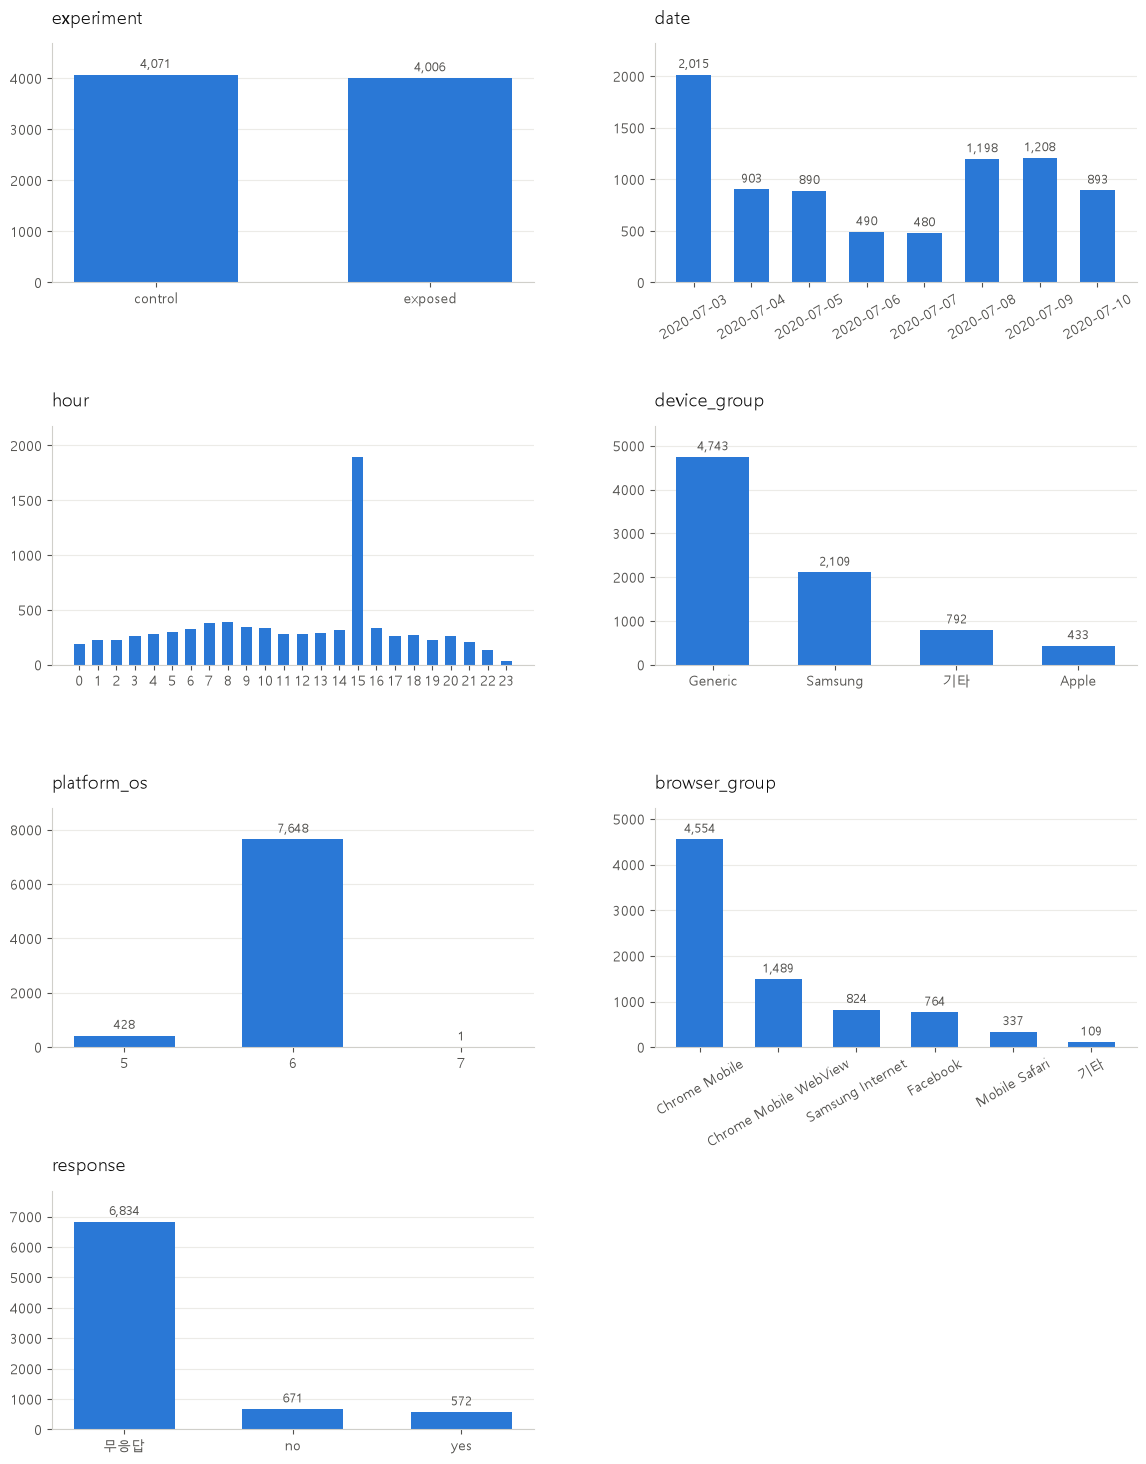

In [32]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"   # 한글 폰트
plt.rcParams["axes.unicode_minus"] = False
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"

plots = [
    ("experiment",    df["experiment"].value_counts()),
    ("date",          df["date"].value_counts().sort_index()),
    ("hour",          df["hour"].value_counts().sort_index()),
    ("device_group",  df["device_group"].value_counts()),
    ("platform_os",   df["platform_os"].value_counts().sort_index()),
    ("browser_group", df["browser_group"].value_counts()),
    ("response",      df["response"].value_counts()),
]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
fig.subplots_adjust(hspace=0.6, wspace=0.25)   # 패널 간 간격 (세로/가로)
for ax, (col, vc) in zip(axes.flat, plots):
    bars = ax.bar(vc.index.astype(str), vc.values, color=BLUE, width=0.6)
    ax.set_title(col, loc="left", fontsize=13, color=INK, pad=14)   # 제목과 도표 사이 간격
    ax.margins(y=0.15)   # 막대 위 숫자 라벨이 제목에 닿지 않도록 위쪽 여백
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#d0cfca")
    ax.tick_params(colors=MUTED)
    ax.grid(axis="y", color="#ecebe7", linewidth=0.8)
    ax.set_axisbelow(True)
    if len(vc) <= 8:   # 막대가 적을 때만 숫자 표시
        ax.bar_label(bars, labels=[f"{v:,}" for v in vc.values], padding=3, color=MUTED, fontsize=9)
    if col in ("date", "browser_group"):
        ax.tick_params(axis="x", rotation=30)
axes.flat[-1].axis("off")   # 남는 칸 숨기기

### ❓ 4. 질문과 가설 설정

#### 🎯 1) 주 질문
- **알고 싶은 것**: SmartAd 광고(creative)를 본 사용자는 더미 광고를 본 사용자보다 브랜드 설문(BIO)에 "Yes"라고 더 많이 답할까?
- **주지표**: 응답자 중 yes 비율 = `yes / (yes + no)`
  - BIO에 응답한 사람(1,243명)만 대상으로 한다. 무응답은 No가 아니라 "의견을 밝히지 않음"이기 때문이다.
  - 보조지표로 전체 노출 대비 응답률 `(yes + no) / 전체`도 함께 본다.
- **가설**
  - $H_0$: exposed 그룹과 control 그룹의 yes 비율은 같다. (광고 효과 없음)
  - $H_1$: exposed 그룹의 yes 비율이 control 그룹보다 높다. (광고 효과 있음)
- **유의수준**: $\alpha = 0.05$
- **단측 검정**: 알고 싶은 것은 "광고가 Yes를 늘렸는가"이고, 늘었을 때만 광고를 도입한다는 결정 기준이 있으므로 방향을 미리 정한다.
  - 단, 단측 검정에서는 "광고가 오히려 Yes를 줄였다"는 결론은 내릴 수 없다. exposed가 더 낮게 나오면 "효과 없음"으로만 해석한다.
- 세그먼트(인앱 / 일반 브라우저, Android / iOS)별 효과를 묻는 추가 질문(2차 검정)은 범위를 줄여 향후 과제로 남긴다. (→ 8단계 3))

### 🧰 5. 검정 고르기

#### 🙋 1) 세 질문에 답하기

| 질문 | 답 |
|---|---|
| 성공 지표가 비율인가, 연속형인가? | **비율(범주형)**. 응답자 한 명마다 yes / no 둘 중 하나이고, 지표는 yes의 비율이다. |
| 비교할 집단은 몇 개인가? | **2개** (exposed vs control) |
| 연속형이라면 정규성·등분산은? | 연속형이 아니므로 해당 없음. 대신 **기대빈도가 충분한지**를 확인한다. |

→ 검정 표에서 **"비율 · 2집단"** → **카이제곱 독립성 검정**

#### 🧮 2) 검정의 원리: 관측 빈도 vs 기대 빈도

- 광고(exposed / control)와 응답(yes / no)이 **관계가 없다면**, 두 집단의 yes 비율은 같아야 한다. 이때 각 칸에서 기대되는 빈도가 **기대 빈도**($E_i$)다.
- 실제로 센 값이 **관측 빈도**($O_i$)다.
- 관측 빈도가 기대 빈도에서 우연이라고 보기 어려울 만큼 벗어났는지를 아래 통계량으로 판단한다.

$$\chi^2 = \sum_i \frac{(O_i - E_i)^2}{E_i}, \qquad E_{ij} = \frac{(\text{행 합계}_i) \times (\text{열 합계}_j)}{\text{전체 합계}}$$

- $O_i$: 실제 관측된 값, $E_i$: 귀무가설이 맞을 때 기대되는 값, $\sum$: 2×2표의 네 칸 전체에 대한 합
- 자유도 = (행 수 − 1) × (열 수 − 1) = **1**

#### ✅ 3) 검정 방법(카이제곱 독립성 검정) 선정 이유

**① 왜 카이제곱인가**

- 지표가 응답자별 yes / no인 **범주형 데이터**다.
- 두 집단(exposed, control)의 **yes 비율이 같은지**를 보는 문제다.
- 따라서 t-검정이 아니라, **관측 빈도와 기대 빈도를 비교하는 카이제곱 검정**이 맞다.

**② 검정의 원리**

- 집단(exposed / control)과 응답(yes / no)으로 **2×2 분할표**를 만든다.
- 귀무가설(광고와 응답이 무관)이 맞다면 각 칸의 **기대 빈도**를 계산할 수 있다.
- 관측 빈도가 기대 빈도에서 얼마나 벗어났는지가 **χ² 값**이다.

**③ 사용 조건과 선택**

| 항목 | 내용 |
|---|---|
| 조건 | 카이제곱 근사는 **기대 빈도가 모든 칸에서 5 이상**일 때 믿을 수 있다. |
| 확인 | 아래 셀에서 **전체**의 기대 빈도를 확인한다. |
| 대안 | 조건을 충족하지 못하면 **Fisher 정확 검정**으로 바꾼다. |
| 연속성 보정 | **쓰지 않는다(Yates 미적용).** 표본이 충분히 크고, 보정을 하면 p값이 보수적으로 나오기 때문이다. |

**④ 주의: χ²는 방향을 말해 주지 않는다**

- χ² 통계량은 제곱한 값이라 **방향 정보가 없다.**
- 이 노트북의 가설은 "exposed가 더 높다"는 **단측**이므로 아래 순서로 판단한다.

  1. 차이(exposed − control)의 **부호가 양(+)인지** 먼저 확인한다.
  2. 양(+)이면 **단측 p = χ² 검정의 양측 p ÷ 2** 로 판단한다.
  3. 음(−)이면 **H0를 기각하지 않는다.**

In [ ]:
# 관측 빈도 · 기대 빈도 표와 조건(기대 빈도 ≥ 5) 확인
resp = df[(df["yes"] + df["no"]) == 1].copy()      # 응답자만 (yes 또는 no 중 하나)
resp["success"] = resp["yes"]                       # yes = 1
resp["exposed"] = (resp["experiment"] == "exposed").astype(int)

print(f"응답자 {len(resp):,}명 (yes {resp['success'].sum():,} / no {(1 - resp['success']).sum():,})")
print()

def show_o_e(d, name):
    obs = pd.crosstab(d["experiment"], d["success"]).rename(columns={0: "no", 1: "yes"})
    exp = pd.DataFrame(stats.contingency.expected_freq(obs.values), index=obs.index, columns=obs.columns)
    print(f"[{name}] 관측 빈도 O")
    print(obs)
    print(f"[{name}] 기대 빈도 E")
    print(exp.round(1))
    print(f"  기대 빈도 최솟값 = {exp.values.min():.1f}  →  "
          f"{'카이제곱 근사 가능 (≥ 5)' if exp.values.min() >= 5 else 'Fisher 정확 검정 권장 (< 5)'}")
    print()

show_o_e(resp, "전체")

### 🧾 6. 검정 수행과 3종 세트 보고

#### 🗓️ 1) 분석 계획 (결과를 보기 전에 확정)

| 분석 | 역할 | 검정 | 유의수준 α | 신뢰구간 |
|---|---|---|---|---|
| 전체 (exposed vs control) | **1차** | 카이제곱 독립성 검정, 단측(p ÷ 2) | 0.05 | 95% |

- 1차(전체)는 보정 없이 α = 0.05로 판단한다.
- 카이제곱 검정은 p값만 주므로, 이 검정에서 얻지 못하는 **차이의 크기와 불확실성**은 3종 세트(점추정 · 신뢰구간 · 효과 크기)로 보완한다. 신뢰구간은 양측으로 구한다.
- 비율 지표이므로 효과 크기는 **절대 차이(%p)** 와 **상대 차이(배수)** 를 함께 보고한다.
- 세그먼트별 효과 검정(2차)은 범위를 줄여 향후 과제로 남긴다. (→ 8단계 3))

In [ ]:
# 카이제곱 독립성 검정 + 3종 세트 계산 함수
def chi_test(d, conf=0.95):
    """d: 응답자 데이터 (success, experiment 컬럼). exposed가 control보다 높은지 검정."""
    e = d[d["experiment"] == "exposed"]["success"]
    c = d[d["experiment"] == "control"]["success"]
    x1, n1 = int(e.sum()), len(e)
    x0, n0 = int(c.sum()), len(c)
    p1, p0 = x1 / n1, x0 / n0
    diff = p1 - p0

    # 검정: 2×2 분할표 (행: exposed, control / 열: yes, no), 연속성 보정 없음
    table = np.array([[x1, n1 - x1], [x0, n0 - x0]])
    chi2, p_two, dof, expected = stats.chi2_contingency(table, correction=False)
    # χ²는 방향 정보가 없으므로, 차이의 부호가 +일 때만 단측 p = 양측 p / 2
    p_one = p_two / 2 if diff > 0 else 1 - p_two / 2
    # 칸별 기여도 (O − E)² / E
    contrib = (table - expected) ** 2 / expected
    # Fisher 정확 검정(단측) — 기대 빈도가 작을 때 대안, 교차 확인용
    p_fisher = stats.fisher_exact(table, alternative="greater")[1]

    # 신뢰구간: 각 집단 비율을 따로 쓴 표준오차 (양측)
    se_unp = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    zc = stats.norm.ppf(1 - (1 - conf) / 2)
    ci = (diff - zc * se_unp, diff + zc * se_unp)

    # 상대 차이(배수) = p1 / p0, 로그 변환으로 신뢰구간
    rr = p1 / p0
    se_log = np.sqrt((1 - p1) / x1 + (1 - p0) / x0)
    rr_ci = (rr * np.exp(-zc * se_log), rr * np.exp(zc * se_log))

    return dict(x1=x1, n1=n1, x0=x0, n0=n0, p1=p1, p0=p0, diff=diff,
                chi2=chi2, dof=dof, p_two=p_two, p_one=p_one, p_fisher=p_fisher,
                exp_min=expected.min(), contrib=contrib,
                se_unp=se_unp, ci=ci, rr=rr, rr_ci=rr_ci, conf=conf)


def report(name, r, alpha):
    """3종 세트(점추정 · 신뢰구간 · 효과 크기)와 검정 결과를 출력"""
    print(f"■ {name}")
    print(f"  control {r['p0']:.1%} ({r['x0']}/{r['n0']})  vs  exposed {r['p1']:.1%} ({r['x1']}/{r['n1']})")
    print(f"  ① 점추정   : exposed − control = {r['diff'] * 100:+.2f} %p")
    print(f"  ② {r['conf']:.1%} 신뢰구간 : [{r['ci'][0] * 100:+.2f}, {r['ci'][1] * 100:+.2f}] %p")
    print(f"  ③ 효과 크기 : 절대 차이 {r['diff'] * 100:+.2f} %p, "
          f"상대 차이 {r['rr']:.2f}배 ({r['conf']:.1%} CI [{r['rr_ci'][0]:.2f}, {r['rr_ci'][1]:.2f}])")
    print(f"  검정       : χ²({r['dof']}) = {r['chi2']:.3f}, 양측 p = {r['p_two']:.4f}, "
          f"차이의 부호 {'+' if r['diff'] > 0 else '−'} → 단측 p = {r['p_one']:.4f}  (기준 α = {alpha:.3f})")
    print(f"  교차 확인  : Fisher 단측 p = {r['p_fisher']:.4f}  |  기대 빈도 최솟값 = {r['exp_min']:.1f}")
    verdict = "H0 기각 (exposed의 yes 비율이 더 높음)" if r["p_one"] < alpha else "H0 기각 못함"
    print(f"  판정       : {verdict}")
    print()

#### 🥇 2) 1차 분석: 전체 exposed vs control (α = 0.05)

In [ ]:
res_all = chi_test(resp, conf=0.95)
report("전체 (1차, α = 0.05)", res_all, alpha=0.05)

# 어느 칸이 χ²에 가장 크게 기여했는가 (O − E)² / E
print("칸별 χ² 기여도 (행: exposed, control / 열: yes, no)")
print(pd.DataFrame(res_all["contrib"], index=["exposed", "control"], columns=["yes", "no"]).round(3))

#### 🩺 3) 보조 확인: 응답률

In [ ]:
# (1) 응답률(보조지표): 광고 자체가 응답 여부를 바꿨는가
df["responded"] = ((df["yes"] + df["no"]) == 1).astype(int)
rate = df.groupby("experiment")["responded"].agg(["sum", "count", "mean"])
rate.columns = ["응답자", "전체 노출", "응답률"]
print(rate.round(4))
tmp = df.assign(success=df["responded"])           # 응답 여부를 0/1 지표로 두고 같은 함수 사용
r_rate = chi_test(tmp, conf=0.95)
print(f"응답률 차이 = {r_rate['diff'] * 100:+.2f} %p, χ² = {r_rate['chi2']:.3f}, "
      f"단측 p = {r_rate['p_one']:.4f}  (기술용, 판정 대상 아님)")
print()

### 🔬 7. 한 걸음 더: 가정이 깨졌다면 (선택 B)

**왜 B인가**
- 지금까지의 모든 검정은 "control과 exposed의 구성이 같다", 즉 **무작위 배정**이라는 가정 위에 서 있다.
- A/B 테스트는 무작위 배정으로 개인 간 차이를 **집단 단위에서 같게** 만들어 광고만 다른 두 집단을 비교하는 설계이므로, 세부 항목(날짜·시간·기기·OS·브라우저)별로도 control과 exposed의 비율이 우연 범위 안에서 비슷해야 한다.
- 앞선 SRM은 전체 비율만 확인했다. 항목별로 쪼개 보면 이 가정이 깨졌을 가능성이 있어(→ 2단계 참고사항), 선택지 중 "가정이 깨졌다면"을 고른다.
- 성공 지표가 yes / no 비율이라 B의 정규성·Q-Q plot·t-검정 / Mann-Whitney는 해당하지 않는다. 대신 **같은 구조(진단 → 방법 비교 → 문제 구간 전후 비교)를 이 데이터의 가정(무작위 배정)에 맞춰 적용한다.**

| B의 단계 | 이 노트북에서 하는 일 |
|---|---|
| 분포 진단 (히스토그램·Q-Q·이상치) | **항목별 SRM**: 날짜·시간·기기·OS·브라우저별 배정 비율 진단 (1) |
| 방법 비교 (t / Mann-Whitney / 부트스트랩) | **단순 카이제곱 vs 층화(Mantel-Haenszel) vs 공변량 보정 로지스틱** 비교 (2) |
| 이상치 제외 전후 비교 | 쏠림이 큰 **07-03 15시 구간 제외 전후** 비교 (2) |

- 하나를 깊게 하는 편이 낫다는 안내에 따라 B 하나로 진행하고, **범위는 전체(1차) 결과가 가정 위반에 흔들리는지까지**로 줄인다. 세그먼트별 효과 검정(2차)은 향후 과제로 남긴다. (→ 8단계 3))

#### 🧩 1) 분포 진단: 항목별 SRM

- **목적**: 무작위 배정이라면 어떤 기준으로 잘라도 control : exposed가 50:50 근처여야 한다. 전체 비율이 맞아도 날짜·시간·기기·OS·브라우저별로 보면 한쪽이 몰려 있을 수 있으므로 값마다 배정 비율을 확인한다.
- **방법**: 변수의 값마다 카이제곱 적합도 검정(기대 비율 50:50). 값이 많아 비교 횟수가 늘어나므로 **변수 안에서 Bonferroni 보정**을 하고, 보정 p < 0.05이면 ⚠️로 표시한다.
- **읽는 법**
  - `z`: 부호가 +이면 exposed 쏠림, −이면 control 쏠림. |z| > 2이면 눈에 띄는 쏠림이다.
  - 표본이 큰 값은 작은 쏠림도 유의하게 나오므로 p값만 보지 말고 `exposed 비율`로 크기를 함께 판단한다.
- **제외 기준**: n < 30인 값은 검정력이 없어 제외한다. `response`는 광고 노출 이후의 결과라 배정 점검에서 뺀다.

In [33]:
from scipy import stats
from IPython.display import display

srm_vars = ["date", "hour", "device_group", "platform_os", "browser_group"]   # response는 광고 노출 이후의 결과라 제외

def srm_by_level(d, col, min_n=30):
    """col의 값마다 control : exposed = 50 : 50 적합도 검정 (n < min_n인 값은 제외)"""
    rows = []
    for k, g in d.groupby(col):
        n_c = int((g["experiment"] == "control").sum())
        n_e = int((g["experiment"] == "exposed").sum())
        n = n_c + n_e
        if n < min_n:
            continue
        chi = stats.chisquare([n_c, n_e])
        rows.append({"변수": col, "값": k, "control": n_c, "exposed": n_e, "n": n,
                     "exposed 비율": round(n_e / n, 3),
                     "z": round((n_e - n / 2) / np.sqrt(n / 4), 2),
                     "χ²": round(chi.statistic, 2), "p": chi.pvalue})
    t = pd.DataFrame(rows)
    if len(t):
        t["p(Bonferroni)"] = (t["p"] * len(t)).clip(upper=1)        # 변수 안의 값 개수만큼 보정
        t["SRM"] = np.where(t["p(Bonferroni)"] < 0.05, "⚠️ 의심", "정상")
    return t

def srm_all(d, min_n=30):
    return pd.concat([srm_by_level(d, c, min_n) for c in srm_vars], ignore_index=True)

srm_full = srm_all(df)

for col in srm_vars:
    print(f"■ {col}별 SRM")
    t = srm_full[srm_full["변수"] == col].drop(columns="변수")
    display(t.sort_values("z").round({"p": 4, "p(Bonferroni)": 4}).reset_index(drop=True))
    print()

■ date별 SRM


,값,control,exposed,n,exposed 비율,z,χ²,p,p(Bonferroni),SRM
0,2020-07-03,1545,470,2015,0.233,-23.95,573.51,0.0000,0.0000,⚠️ 의심
1,2020-07-07,223,257,480,0.535,1.55,2.41,0.1207,0.9655,정상
2,2020-07-04,426,477,903,0.528,1.70,2.88,0.0897,0.7173,정상
3,2020-07-06,196,294,490,0.600,4.43,19.60,0.0000,0.0001,⚠️ 의심
4,2020-07-05,362,528,890,0.593,5.56,30.96,0.0000,0.0000,⚠️ 의심
5,2020-07-10,355,538,893,0.602,6.12,37.50,0.0000,0.0000,⚠️ 의심
6,2020-07-08,484,714,1198,0.596,6.65,44.16,0.0000,0.0000,⚠️ 의심
7,2020-07-09,480,728,1208,0.603,7.14,50.91,0.0000,0.0000,⚠️ 의심



■ hour별 SRM


,값,control,exposed,n,exposed 비율,z,χ²,p,p(Bonferroni),SRM
0,15,1673,222,1895,0.117,-33.33,1111.03,0.0000,0.0000,⚠️ 의심
1,23,14,17,31,0.548,0.54,0.29,0.5900,1.0000,정상
2,0,90,104,194,0.536,1.01,1.01,0.3148,1.0000,정상
3,21,94,112,206,0.544,1.25,1.57,0.2098,1.0000,정상
4,22,60,75,135,0.556,1.29,1.67,0.1967,1.0000,정상
5,19,102,125,227,0.551,1.53,2.33,0.1269,1.0000,정상
6,16,152,183,335,0.546,1.69,2.87,0.0903,1.0000,정상
7,17,110,153,263,0.582,2.65,7.03,0.0080,0.1923,정상
8,2,91,139,230,0.604,3.17,10.02,0.0016,0.0372,⚠️ 의심
9,3,105,161,266,0.605,3.43,11.79,0.0006,0.0143,⚠️ 의심



■ device_group별 SRM


,값,control,exposed,n,exposed 비율,z,χ²,p,p(Bonferroni),SRM
0,Apple,311,122,433,0.282,-9.08,82.50,0.0000,0.0,⚠️ 의심
1,Generic,2411,2332,4743,0.492,-1.15,1.32,0.2513,1.0,정상
2,Samsung,1041,1068,2109,0.506,0.59,0.35,0.5566,1.0,정상
3,기타,308,484,792,0.611,6.25,39.11,0.0000,0.0,⚠️ 의심



■ platform_os별 SRM


,값,control,exposed,n,exposed 비율,z,χ²,p,p(Bonferroni),SRM
0,5,308,120,428,0.280,-9.09,82.58,0.000,0.000,⚠️ 의심
1,6,3763,3885,7648,0.508,1.40,1.95,0.163,0.326,정상



■ browser_group별 SRM


,값,control,exposed,n,exposed 비율,z,χ²,p,p(Bonferroni),SRM
0,Facebook,561,203,764,0.266,-12.95,167.75,0.0000,0.0000,⚠️ 의심
1,Mobile Safari,246,91,337,0.270,-8.44,71.29,0.0000,0.0000,⚠️ 의심
2,Samsung Internet,492,332,824,0.403,-5.57,31.07,0.0000,0.0000,⚠️ 의심
3,Chrome Mobile,2410,2144,4554,0.471,-3.94,15.54,0.0001,0.0005,⚠️ 의심
4,기타,70,39,109,0.358,-2.97,8.82,0.0030,0.0179,⚠️ 의심
5,Chrome Mobile WebView,292,1197,1489,0.804,23.45,550.05,0.0000,0.0000,⚠️ 의심


#### 🧐 1-1) 항목별 SRM 결과 해석

**요약**
- 무작위 배정은 집단 구성을 같게 만드는 장치인데, 이 데이터는 측정된 변수(날짜·시간·브라우저·기기)에서 이미 균형이 깨져서 두 집단의 차이를 광고 효과로 해석할 수 없다.
- 전체 비율이 50:50에 가까워 보이는 것은 **07-03의 control 쏠림이 나머지 날들의 exposed 쏠림을 상쇄**했기 때문이다.

**날짜별**
- 07-03만 control 쪽으로 크게 치우쳤고(exposed 23.3%), 나머지 7일 중 5일은 exposed가 약 60%이다. (07-04, 07-07은 보정 후에도 정상 범위)
- **07-03을 제외한 7일을 합치면 control 2,526 / exposed 3,536 (exposed 58.3%)로 SRM이 깨진다.** (07-03 15시 구간만 빼도 2,530 / 4,001, 61.3%)
- 즉 전체 SRM 통과(p = 0.47)는 배정이 고르다는 증거가 아니라 **서로 반대 방향의 쏠림이 우연히 상쇄된 결과**이다.
- exposed 쏠림이 거의 매일 반복되므로 특정 날짜의 일회성 문제가 아니다.

**시간별**
- 15시는 control 1,673 / exposed 222 (exposed 11.7%)로 control 쪽에 크게 몰려 있다. 대부분 07-03 15시 구간이다.
- 15시를 뺀 나머지 시간대는 대체로 exposed 쪽이며(약 54~69%), 24개 시간대 중 17개(15시 포함)가 Bonferroni 보정 후에도 의심으로 나온다.
- 특정 시간대의 문제가 아니라 하루 전반에서 exposed 쏠림이 나타난다.

**브라우저별**
- 브라우저마다 **방향이 반대**다. Chrome Mobile WebView는 exposed 80.4%, Facebook(26.6%)·Mobile Safari(27.0%)는 control 쪽으로 쏠려 있다.
- WebView와 Facebook은 둘 다 앱 안에 내장된 브라우저인데도 쏠림 방향이 반대다. 묶어서 보면 서로 상쇄되어 가려지므로 **브라우저 단위**로 봐야 실체가 드러난다.
- Chrome Mobile은 쏠림이 작지만(47.1%) 표본이 커서 통계적으로는 유의하다. 크기로 보면 약한 쏠림이다.

**기기·OS별**
- Apple(iOS 기기)은 exposed 28.2%로 control 쪽, 기타 기기는 61.1%로 exposed 쪽으로 쏠려 있다. iOS(`platform_os = 5`)도 28.0%로 같은 패턴이다. iOS는 Safari 계열 브라우저와 거의 겹치므로 브라우저 쏠림이 기기·OS에 반영된 것으로 보인다.
- Samsung(50.6%)과 Android(50.8%)는 전체로는 정상이다. 하지만 Android 안의 브라우저별로는 WebView(80.4%)와 Facebook(26.6%)처럼 **반대 방향 쏠림이 상쇄**된 결과로 보인다. "정상"이라고 해서 안심할 수 없다.

**종합 해석**
- **전체 SRM 통과 ≠ 무작위 배정 확인.** 날짜, 시간, 브라우저, 기기 모두에서 큰 쏠림이 나오고, 이들이 서로 상쇄되어 전체가 맞아 보일 뿐이다.
- 쏠림이 한 곳이 아니라 여러 변수에 걸쳐 있으므로, 배정 로직이나 노출 로깅이 환경(브라우저)에 따라 다르게 작동했을 가능성이 있다. 이 데이터만으로는 **원인을 확정할 수 없다.**
- 가능한 가설 (확인 필요): ① exposed 광고가 특정 환경에서만 노출·기록이 잘 됨, ② 07-03에 control만 먼저 집행됨, ③ 브라우저별로 트래픽 배분 규칙이 다름.
- **분석에 미치는 영향**: 그룹 간 yes 비율 차이가 광고 효과인지, 그룹의 브라우저·날짜 구성 차이인지 구분하기 어렵다. 그래서 아래 2)에서 층화·보정으로 1차 결과의 결론이 바뀌는지 확인한다.
- **후속 조치**: 실험 담당자에게 배정 규칙과 노출 로깅 방식을 확인하고, 필요하면 재실험을 요청한다.

#### 🛠️ 2) 1차 결과가 가정 위반에 흔들리는가: 보정·민감도 (전체)

1)에서 쏠림이 확인되었으므로 6단계의 단순 비교는 구성 차이에 오염되었을 수 있다. B의 "방법 비교"와 "문제 구간 전후 비교"로 **1차 결과의 결론이 바뀌지 않는지** 확인한다. 범위는 전체(1차) 하나이다.

1. **단순 카이제곱**: 6단계의 결과 (기준선)
2. **날짜별 층화 (Mantel-Haenszel)**: 같은 날짜끼리만 비교한 뒤 합침
3. **브라우저별 층화 (Mantel-Haenszel)**: 같은 브라우저끼리만 비교한 뒤 합침. 쏠림이 브라우저 단위로 가장 컸으므로 이 보정이 핵심이다.
4. **공변량 보정 로지스틱**: `success ~ exposed + C(date) + C(browser_group)`에서 exposed의 보정 오즈비

위 비교를 **07-03 15시 구간을 포함한 경우와 제외한 경우** 모두에서 한다.
- 07-03 15시를 제외하면 전체 SRM이 오히려 깨지므로(2,530 / 4,001), 이 비교는 "제외하면 해결된다"가 아니라 **"결론이 이 구간에 의존하는가"** 를 보는 용도이다.

In [ ]:
# 쏠림이 가장 큰 07-03 15시 구간 표시
df["hour_num"] = pd.to_numeric(df["hour"], errors="coerce")
df["spike"] = (df["date"].astype(str) == "2020-07-03") & (df["hour_num"] == 15)
resp["spike"] = df.loc[resp.index, "spike"]

# 비교 대상: 전체 (원본) vs 전체 (07-03 15시 제외)
targets = [("전체 (원본)", resp), ("전체 (07-03 15시 제외)", resp[~resp["spike"]])]

# (1) 단순 카이제곱: 07-03 15시 제외 전후
rows = []
for name, d in targets:
    r = chi_test(d, conf=0.95)
    rows.append({"분석": name, "n(응답자)": r["n0"] + r["n1"],
                 "control yes%": round(r["p0"] * 100, 2), "exposed yes%": round(r["p1"] * 100, 2),
                 "차이(%p)": round(r["diff"] * 100, 2),
                 "CI 하한": round(r["ci"][0] * 100, 2), "CI 상한": round(r["ci"][1] * 100, 2),
                 "단측 p": round(r["p_one"], 4), "유의(α=0.05)": "✅" if r["p_one"] < 0.05 else "—"})
pd.DataFrame(rows)

In [ ]:
# (2)(3) 층화 Mantel-Haenszel: 날짜별 / 브라우저별  (같은 층 안에서만 exposed vs control 비교)
from statsmodels.stats.contingency_tables import StratifiedTable

def mh_by(d, label, by):
    tables = []
    for _, g in d.groupby(by):
        t = pd.crosstab(g["experiment"], g["success"]).reindex(
            index=["exposed", "control"], columns=[1, 0], fill_value=0).values
        if (t.sum(axis=0) > 0).all() and (t.sum(axis=1) > 0).all():   # 정보 없는 층 제외
            tables.append(t)
    if len(tables) < 2:
        return {"분석": label, "층 기준": by, "사용한 층 수": len(tables), "합동 오즈비": np.nan,
                "95% CI": "층이 부족함", "양측 p": np.nan, "단측 p": np.nan}
    st = StratifiedTable(tables)
    or_p = st.oddsratio_pooled
    lo, hi = st.oddsratio_pooled_confint()
    p_two = st.test_null_odds(correction=False).pvalue
    p_one = p_two / 2 if or_p > 1 else 1 - p_two / 2
    return {"분석": label, "층 기준": by, "사용한 층 수": len(tables),
            "합동 오즈비": round(or_p, 2), "95% CI": f"[{lo:.2f}, {hi:.2f}]",
            "양측 p": round(p_two, 4), "단측 p": round(p_one, 4)}

pd.DataFrame([mh_by(d, name, by) for name, d in targets for by in ["date", "browser"]])

In [ ]:
# (4) 공변량 보정 로지스틱: 날짜 + 브라우저를 통제한 exposed의 보정 오즈비
import warnings
import statsmodels.formula.api as smf

def adj_logit_f(d, label, formula):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = smf.logit(formula, data=d).fit(disp=0)
        b = m.params["exposed"]
        ci = m.conf_int().loc["exposed"]
        p_two = m.pvalues["exposed"]
        p_one = p_two / 2 if b > 0 else 1 - p_two / 2
        return {"분석": label, "n": int(m.nobs), "보정 오즈비": round(np.exp(b), 2),
                "95% CI": f"[{np.exp(ci[0]):.2f}, {np.exp(ci[1]):.2f}]", "단측 p": round(p_one, 4),
                "수렴": "O" if m.mle_retvals.get("converged", True) else "X (결과 주의)"}
    except Exception as e:      # 완전 분리 등으로 수렴 실패할 수 있음
        return {"분석": label, "n": len(d), "보정 오즈비": np.nan, "95% CI": f"실패: {type(e).__name__}",
                "단측 p": np.nan, "수렴": "X"}

F = "success ~ exposed + C(date) + C(browser_group)"
pd.DataFrame([adj_logit_f(d, name, F) for name, d in targets])

**읽는 법**
- 단순 카이제곱, 날짜별 MH, 브라우저별 MH, 보정 회귀, 07-03 15시 제외 전후에서 **차이의 방향과 유의 여부가 같으면** 1차 결과가 쏠림에 크게 흔들리지 않는다는 근거가 된다.
- **브라우저별 MH 결과가 단순 비교와 크게 다르면** 차이가 브라우저 구성(어떤 브라우저에 exposed가 몰렸는지)에서 나온 것일 수 있다. 방법에 따라 결론이 바뀌면 "결과가 배정 불균형에 민감하다"고 보고하고 단정하지 않는다.
- 보정은 **관측된** 날짜·브라우저 차이만 고친다. 노출 로깅 자체가 다르게 되는 문제는 분석으로 고칠 수 없다.
- 보정 로지스틱에서 "수렴 X"가 나오면 그 행은 쓰지 않는다.

### 🏁 8. 의사결정과 한계

#### 🧭 1) 의사결정: 보류하고 데이터 추가 수집(재실험)
- **결과**: 1차 분석(전체)에서 exposed의 yes 비율은 control보다 +1.83%p 높았지만(46.9% vs 45.1%), 95% 신뢰구간이 0을 넓게 포함하고([-3.7, +7.4]%p) 단측 p = 0.26으로 유의하지 않았다. (6단계 실행 결과 기준)
- **가정 점검**: 항목별 SRM에서 날짜·시간·브라우저·기기 전반에 쏠림이 확인되어 **무작위 배정이 확인되지 않았다.** 보정·민감도(7단계 2))에서 1차 결과의 방향이 유지되는지 확인한 뒤 이 결론을 확정한다.
- **의사결정**: 출시할 근거가 부족하다 → **보류**하고, 배정 규칙과 노출 로깅을 확인한 뒤 **데이터를 추가 수집(재실험)** 한다.

#### 🚨 2) 한계와 해석 시 주의

- **무작위 배정이 확인되지 않음**: 전체 SRM은 통과했지만 항목별 SRM(7단계)에서 날짜·시간·브라우저·기기 전반에 큰 쏠림이 나타났다. 서로 반대 방향의 쏠림이 상쇄되어 전체가 맞아 보였을 뿐이다. 그래서 두 집단의 차이를 광고의 인과 효과로 해석할 수 없고, 층화·보정은 관측된 변수(날짜·브라우저)의 차이만 줄인다. 노출 로깅 차이 같은 관측되지 않은 원인은 분석으로 보정할 수 없으므로 실험 담당자에게 확인이 필요하다.
- **응답자만 분석한다는 점**: 응답 여부는 광고를 본 뒤의 결과이므로, 광고가 응답률을 바꿨다면 exposed와 control의 응답자는 서로 다른 사람들이 섞인 집단일 수 있다. yes 비율의 차이가 광고의 순수한 효과라고 단정할 수 없다. 6단계의 응답률 비교를 함께 보고, 응답률이 크게 다르면 해석을 더 조심한다.
- **카이제곱 검정은 방향을 말해 주지 않음**: χ²가 크다는 것은 "두 집단이 다르다"는 뜻일 뿐이다. 이 노트북은 차이의 부호가 +일 때만 p ÷ 2로 단측 판정을 했고, exposed가 더 낮게 나오면 "효과 없음"으로만 해석한다. "광고가 yes를 줄였다"는 결론은 내리지 않는다.
- **p값만으로는 크기를 알 수 없음**: χ² 검정은 차이가 있는지를 알려 줄 뿐 얼마나 큰지는 말하지 않으므로, 3종 세트(%p 차이, 신뢰구간, 상대 차이)를 함께 읽는다.
- **유의하지 않음 ≠ 효과 없음**: 응답자가 1,243명뿐이라 작은 효과는 감지하지 못했을 수 있다. 신뢰구간이 넓다면 "효과가 없다"가 아니라 "이 표본으로는 판단하기 어렵다"고 쓴다.
- **07-03 15시 control 쏠림**: 이 구간은 control 쪽으로 몰렸지만 나머지 시간대는 exposed 쪽으로 치우쳐 있어, 구간을 제외해도 쏠림이 해결되지 않는다(제외하면 오히려 전체 SRM이 깨진다). 제외 전후로 결론이 바뀌는지는 7단계 2)에서 확인했다.
- **세그먼트별 효과는 검정하지 않음**: 환경(브라우저·OS)에 따라 효과가 다를 수 있으나 이번 범위에서는 다루지 않았다. (→ 3) 향후 과제)
- **관찰 기간**: 8일 데이터이고 요일 구성이 고르지 않다(07-03 금요일이 가장 많음). 다른 기간에 같은 결과가 나온다고 보장할 수 없다.

#### 🔭 3) 향후 과제

**세그먼트별 효과 검정 (2차 검정)**: 이번에는 범위를 줄여 전체(1차) 결과와 배정 가정 점검까지만 다뤘다. 아래는 후속으로 남긴다.
- 인앱 / 일반 브라우저, Android / iOS별 카이제곱 검정 (단측, 세그먼트 가설군별 Bonferroni, 신뢰구간 97.5%)
- 세그먼트 간 효과 차이: 노출 × 플랫폼 상호작용 검정 (양측)
- 세그먼트 안의 배정(SRM)과 응답자 수(기대 빈도 ≥ 5) 확인

**선행 조건**
- 항목별 SRM에서 쏠림의 단위가 **브라우저**로 나타났으므로, 세그먼트별 비교는 브라우저로 층화하거나 배정 문제를 해결한 재실험 데이터로 하는 것이 바람직하다.
- iOS는 응답자가 적어 신뢰구간이 넓어질 것으로 예상되며, Safari 계열 브라우저와 겹쳐 OS 효과와 브라우저 효과를 분리하기 어렵다.

**그 밖의 후속**
- 선택지 A: 이 표본으로 잡을 수 있는 최소 효과(MDE)와 필요 표본 크기 계산